In [1]:
# Classificação Automática de Atividades Culturais e Educacionais
# 07 - Grupos só com o treino e rótulos automáticos
#
# Integrantes: Beatriz Aparecida de Mello Barbosa (10354067), Bruna Gonçalves Corte David (10425696),
#              Henrique Brainer Costa (10420717), João Pedro Queiroz de Andrade (10425822),
#              Júlia Andrade (10428513)
#
# Conteúdo: recalcula os 16 grupos usando só as atividades de treino, mede a semelhança de cada
#           atividade com cada categoria e escolhe, só no treino, a regra que dá mais de uma
#           categoria por atividade. No fim, salva a lista de categorias de cada atividade.
#
# Alterações:
#   11/10/2026 - Bruna - notebook novo, com os grupos recalculados sem o teste e a rotulagem
#                        com mais de uma categoria por atividade

Este notebook faz duas coisas: primeiro recalcula os 16 grupos da Parte 2 usando só as atividades de
treino, para as 139 do teste valerem como atividades novas, e depois dá a cada atividade uma lista de
categorias em ordem, que pode ter mais de uma.

A regra que seguimos do começo ao fim é que tudo que é escolha (os centros, a regra do multirrótulo, os
valores dela) é feito olhando só o treino, e o teste só recebe o resultado pronto. Os experimentos que
nos levaram a cada decisão estão no notebook 06.

In [2]:
# ====================================================================================================
#                       CARREGAMENTO DAS ATIVIDADES, DOS GRUPOS E DOS EMBEDDINGS
# ====================================================================================================
import pandas as pd                  # leitura e manipulação das tabelas
import numpy as np                   # contas com vetores e matrizes
import matplotlib.pyplot as plt      # gráficos que vão para o artigo
from sklearn.cluster import KMeans   # o mesmo agrupamento do notebook 05

activities = pd.read_csv("../data/03_processed/05_activities_clustered.csv", sep=";", encoding="utf-8-sig")    # atividades com a divisão treino/teste e o grupo da Parte 2
clusters_summary = pd.read_csv("../data/03_processed/05_clusters_summary.csv", sep=";", encoding="utf-8-sig")  # o nome que demos a cada grupo
activity_embeddings = np.load("../data/03_processed/03_embeddings.npy")                                        # vetores do notebook 03, na mesma ordem das linhas da tabela

is_train = (activities["split"] == "train").values   # a atividade é do treino?
is_test = ~is_train                                  # ou do teste

print("Atividades:", len(activities), "| Treino:", is_train.sum(), "| Teste:", is_test.sum())

Atividades: 693 | Treino: 554 | Teste: 139


## Os grupos só com o treino

Para recalcular os grupos só com o treino, não adianta rodar o K-Means de novo com a mesma semente,
porque a semente só decide onde os centros são colocados no começo, e com outro conjunto de atividades
esse sorteio cai em outros lugares (no experimento 9 do notebook 06, só 73% das atividades ficaram na
mesma categoria desse jeito, e o grupo de Reciclagem se desfez). Por isso pulamos o sorteio: o K-Means
começa nos centros dos 16 grupos da Parte 2, calculados só com as atividades de treino, e segue dali
(experimento 11).

In [3]:
# ====================================================================================================
#                              OS 16 GRUPOS RECALCULADOS SÓ COM O TREINO
# ====================================================================================================
number_of_clusters = 16                                                                # os grupos da Parte 2
cluster_in_part_2 = activities["cluster"].values                                       # grupo em que cada atividade caiu no notebook 05
category_in_part_2 = activities["category"].to_numpy()                                 # categoria que cada atividade recebeu no notebook 05
name_of_each_cluster = clusters_summary.set_index("cluster")["given_name"].to_dict()   # grupo -> categoria

starting_centers = []                                                                                         # um ponto de partida por grupo
for cluster_number in range(number_of_clusters):
    train_embeddings_of_the_cluster = activity_embeddings[is_train & (cluster_in_part_2 == cluster_number)]   # só as atividades de treino do grupo
    starting_centers.append(train_embeddings_of_the_cluster.mean(axis=0))                                     # o ponto de partida é a média delas
starting_centers = np.array(starting_centers)                                                                 # lista vira matriz de 16 linhas

kmeans = KMeans(n_clusters=number_of_clusters, init=starting_centers, n_init=1)   # sem sorteio: começa nos centros que entregamos
kmeans.fit(activity_embeddings[is_train])                                         # o teste não participa

cluster_of_each_activity = np.zeros(len(activities), dtype=int)                                        # grupo de cada atividade, agora sem o teste ter ajudado a formar
cluster_of_each_activity[is_train] = kmeans.labels_                                                    # o treino fica no grupo em que o K-Means o deixou
cluster_of_each_activity[is_test] = kmeans.predict(activity_embeddings[is_test])                       # o teste vai para o centro mais perto
category_of_each_activity = pd.Series(cluster_of_each_activity).map(name_of_each_cluster).to_numpy()   # o nome do grupo vira a categoria

kept_cluster_in_train = cluster_of_each_activity[is_train] == cluster_in_part_2[is_train]   # o treino ficou no mesmo grupo?
kept_category_in_test = category_of_each_activity[is_test] == category_in_part_2[is_test]   # o teste ficou na mesma categoria?

print("Iterações até o K-Means parar:", kmeans.n_iter_)
print("Treino no mesmo grupo da Parte 2:", kept_cluster_in_train.sum(), "de", is_train.sum())
print("Teste na mesma categoria da Parte 2:", kept_category_in_test.sum(), "de", is_test.sum(), "(", round(100 * kept_category_in_test.mean(), 1), "% )")

Iterações até o K-Means parar: 1
Treino no mesmo grupo da Parte 2: 554 de 554
Teste na mesma categoria da Parte 2: 125 de 139 ( 89.9 % )


In [4]:
# ----------------------------------------------------------------------------------------------------
#                           AS ATIVIDADES DE TESTE QUE MUDARAM DE CATEGORIA
# ----------------------------------------------------------------------------------------------------
test_activities_that_changed = activities.loc[is_test, ["title", "category"]][~kept_category_in_test].copy()            # título e categoria da Parte 2
test_activities_that_changed["category_with_train_only"] = category_of_each_activity[is_test][~kept_category_in_test]   # categoria pelos grupos recalculados
test_activities_that_changed

,title,category,category_with_train_only
2,JARDIM SECRETO – UM DIA PLANTANDO SONHOS COM E...,Infância e Brincadeiras,Literatura e Leitura
56,ESCREVENDO MINHA CANÇÃO – COM EQUIPE BIBLIOTECA,Artes Visuais,Literatura e Leitura
70,ANTES DA ANIMAÇÃO: BRINQUEDOS ÓPTICOS – COM EQ...,Artesanato,"Shows, Espetáculos e Performances"
72,DIA DO SACI | JAXY JATERÊ – CONFECÇÃO DE MARCA...,Artesanato,Literatura e Leitura
76,OFICINA CRIATIVA – VIRADA SUSTENTÁVEL,Reciclagem e Sustentabilidade,Artes Visuais
223,Luta olímpica com Aline Silva,Esporte,Cinema
296,Natureza e Bem-Estar: Descubra Poços de Caldas...,Plantas e Alimentação,Esporte
369,Breve História do Tarot,"Shows, Espetáculos e Performances",Sociedade e Debates
380,Nhemboaty Nhemonguetá: Roda de escuta Guarani,Literatura e Leitura,Sociedade e Debates
513,Online - Tecnologia e o futuro das proteínas,Plantas e Alimentação,Sociedade e Debates


O K-Means parou na 1ª iteração e as 554 atividades de treino ficaram no mesmo grupo da Parte 2, então os
16 grupos continuam existindo, com os mesmos nomes.

No teste, 125 das 139 atividades (89,9%) ficaram na mesma categoria e 14 mudaram, as da tabela acima.
São atividades que ficam entre dois assuntos, como "Jardim Secreto" (de Infância para Literatura) e
"Breve História do Tarot" (de Shows para Sociedade e Debates). No experimento 11 eram 126, e a diferença
de uma atividade vem de mantermos aqui as 3 atividades de descrição quebrada, que lá ficaram de fora.

In [5]:
# ----------------------------------------------------------------------------------------------------
#                              GUARDAR OS CENTROS E O NOME DE CADA GRUPO
# ----------------------------------------------------------------------------------------------------
cluster_centers = kmeans.cluster_centers_                                        # os 16 centros finais, calculados só com o treino
cluster_names = pd.DataFrame({"cluster": range(number_of_clusters)})             # uma linha por grupo
cluster_names["category"] = cluster_names["cluster"].map(name_of_each_cluster)   # a categoria de cada grupo

np.save("../models/cluster_centers.npy", cluster_centers)                                         # a API vai precisar deles para o aviso de revisão
cluster_names.to_csv("../models/cluster_names.csv", sep=";", index=False, encoding="utf-8-sig")   # e do nome de cada um

print("Centros salvos em models/cluster_centers.npy:", cluster_centers.shape)
cluster_names

Centros salvos em models/cluster_centers.npy: (16, 1024)


,cluster,category
0,0,Literatura e Leitura
1,1,Atividade Física e Bem-Estar
2,2,Cultura e Identidade
3,3,"Shows, Espetáculos e Performances"
4,4,Esporte
5,5,Música
6,6,Sociedade e Debates
7,7,Artesanato
8,8,Esporte
9,9,Infância e Brincadeiras


## A régua de proximidade

Para treinar um classificador, cada atividade de treino precisa de uma lista de categorias, e rotular as
554 à mão não cabe no tempo do grupo. A régua faz isso de forma automática, sem ninguém ler atividade
por atividade: ela mede o quanto cada atividade se parece com cada uma das 13 categorias e, com uma
regra escolhida mais abaixo, transforma essas medidas na lista de categorias da atividade. São essas
listas que os classificadores do notebook 09 aprendem. Nós só entramos depois, no notebook 08, rotulando
uma amostra do teste para medir se a régua e os classificadores acertam.

A conta usa os centros que acabamos de calcular. A semelhança entre a atividade e cada grupo é a
similaridade de cosseno entre o vetor da atividade e o centro do grupo (perto de 1 é muito parecido), e,
como Esporte tem três grupos e Shows tem dois, a semelhança com a categoria é a do grupo mais parecido
dela, e não a média dos grupos, porque uma atividade de natação não precisa parecer com futsal para ser
de Esporte. No fim, cada atividade tem 13 números, um por categoria, e chamamos esse conjunto de régua
porque ele mede o quanto a atividade está perto de cada categoria.

In [6]:
# ====================================================================================================
#                       A RÉGUA: SEMELHANÇA DE CADA ATIVIDADE COM CADA CATEGORIA
# ====================================================================================================
normalized_embeddings = activity_embeddings / np.linalg.norm(activity_embeddings, axis=1, keepdims=True)   # vetores com comprimento 1
normalized_centers = cluster_centers / np.linalg.norm(cluster_centers, axis=1, keepdims=True)              # centros com comprimento 1
similarity_to_clusters = normalized_embeddings @ normalized_centers.T                                      # cosseno de cada atividade com cada um dos 16 centros

category_names = sorted(set(name_of_each_cluster.values()))   # as 13 categorias, em ordem alfabética

similarity_to_categories = []                                                                                                                              # uma coluna por categoria
for category_name in category_names:
    clusters_of_the_category = [cluster_number for cluster_number in range(number_of_clusters) if name_of_each_cluster[cluster_number] == category_name]   # os grupos que têm esse nome
    similarity_to_categories.append(similarity_to_clusters[:, clusters_of_the_category].max(axis=1))                                                       # vale o grupo mais parecido
similarity_to_categories = np.array(similarity_to_categories).T                                                                                            # formato atividade x categoria

print("Tabela da régua:", similarity_to_categories.shape)
pd.DataFrame(similarity_to_categories, columns=category_names).round(2).head(3).T   # os 13 números das 3 primeiras atividades

Tabela da régua: (693, 13)


,0,1,2
Artes Visuais,0.70,0.75,0.55
Artesanato,0.60,0.63,0.56
Atividade Física e Bem-Estar,0.60,0.59,0.45
Cinema,0.42,0.55,0.44
Cultura e Identidade,0.54,0.70,0.51
Esporte,0.54,0.52,0.51
Infância e Brincadeiras,0.62,0.76,0.63
Literatura e Leitura,0.60,0.73,0.62
Música,0.48,0.58,0.53
Plantas e Alimentação,0.50,0.59,0.57


A 1ª categoria de cada atividade é a de maior semelhança, que é a resposta de categoria única, a mesma
ideia da Parte 2. Conferimos em quantas atividades ela coincide com a categoria do grupo em que o
K-Means colocou a atividade, o que pode não acontecer em todas, porque o K-Means mede distância em linha
reta e a régua mede cosseno.

In [7]:
# ----------------------------------------------------------------------------------------------------
#                           A 1ª CATEGORIA DA RÉGUA É A DO GRUPO DO K-MEANS?
# ----------------------------------------------------------------------------------------------------
first_category = np.array(category_names)[similarity_to_categories.argmax(axis=1)]   # a categoria mais parecida de cada atividade
first_is_the_cluster_category = first_category == category_of_each_activity          # coincide com o grupo do K-Means?

print("Treino:", first_is_the_cluster_category[is_train].sum(), "de", is_train.sum())
print("Teste: ", first_is_the_cluster_category[is_test].sum(), "de", is_test.sum())
print("Total: ", first_is_the_cluster_category.sum(), "de", len(activities), "(", round(100 * first_is_the_cluster_category.mean(), 1), "% )")

Treino: 554 de 554
Teste:  132 de 139
Total:  686 de 693 ( 99.0 % )


No treino, a 1ª categoria da régua é a do grupo nas 554 atividades, e no teste, em 132 das 139, somando
686 de 693 (99,0%). As 7 de diferença são atividades de teste que ficam entre dois centros, em que as
duas medidas desempatam para lados diferentes. Daqui em diante, a 1ª categoria é a da régua.

## As regras candidatas para as categorias seguintes

Falta decidir quando a atividade recebe uma 2ª ou uma 3ª categoria, e do notebook 06 saíram três regras
possíveis, todas em cima dos 13 números da régua:

- **Diferença** (experimento 2): a atividade recebe também a 2ª categoria se ela quase empata com a 1ª,
  e testamos cortes de 0,005 a 0,05.
- **Beirada** (experimento 6): a atividade recebe toda categoria em que a semelhança passa da beirada
  dela, que é o valor que 90% das atividades de treino daquela categoria ultrapassam.
- **Fatias** (experimento 7): os 13 números viram fatias que somam 100%, pela conta do softmax com
  temperatura, e a atividade recebe toda categoria com uma fatia mínima. Testamos temperaturas de 0,01 a
  0,05 e fatias mínimas de 15% a 30%.

Nas três, a 1ª categoria entra sempre, e todas as contas daqui até a escolha usam só o treino.

In [8]:
# ====================================================================================================
#                                      AS TRÊS REGRAS CANDIDATAS
# ====================================================================================================
def mark_first_category(similarities):
    has_label = np.zeros(similarities.shape, dtype=bool)                          # tabela atividade x categoria: a atividade recebe a categoria?
    has_label[np.arange(len(similarities)), similarities.argmax(axis=1)] = True   # a categoria mais parecida entra sempre
    return has_label

def labels_by_difference(similarities, cutoff):
    has_label = mark_first_category(similarities)                                                                                      # começa só com a 1ª categoria
    row_numbers = np.arange(len(similarities))                                                                                         # 0, 1, 2... para pegar um valor por linha
    categories_from_closest = np.argsort(-similarities, axis=1)                                                                        # categorias da mais parecida para a menos
    difference = similarities[row_numbers, categories_from_closest[:, 0]] - similarities[row_numbers, categories_from_closest[:, 1]]   # distância entre a 1ª e a 2ª
    is_near_tie = difference <= cutoff                                                                                                 # quase empate
    has_label[row_numbers[is_near_tie], categories_from_closest[is_near_tie, 1]] = True                                                # quem quase empata recebe também a 2ª
    return has_label

def labels_by_border(similarities, border_of_each_category):
    return mark_first_category(similarities) | (similarities >= border_of_each_category)   # a 1ª, mais toda categoria acima da beirada

def softmax_with_temperature(similarities, temperature):
    scaled_similarities = similarities / temperature                                             # temperatura baixa aumenta a distância entre as categorias
    scaled_similarities = scaled_similarities - scaled_similarities.max(axis=1, keepdims=True)   # tira o maior valor de cada linha, para a exponencial não estourar
    exponentials = np.exp(scaled_similarities)                                                   # a exponencial deixa tudo positivo e destaca os maiores
    return exponentials / exponentials.sum(axis=1, keepdims=True)                                # divide pela soma da linha: as fatias somam 1

def labels_by_shares(similarities, temperature, minimum_share):
    return mark_first_category(similarities) | (softmax_with_temperature(similarities, temperature) >= minimum_share)   # a 1ª, mais toda categoria com fatia suficiente

train_similarities = similarity_to_categories[is_train]   # a régua só das atividades de treino
train_categories = category_of_each_activity[is_train]    # a categoria (do grupo) de cada atividade de treino

border_of_each_category = np.array([np.percentile(train_similarities[train_categories == category_name, category_position], 10) for category_position, category_name in enumerate(category_names)])   # percentil 10 dos membros de treino de cada categoria

pd.Series(border_of_each_category, index=category_names).round(2)

Artes Visuais                        0.66
Artesanato                           0.62
Atividade Física e Bem-Estar         0.65
Cinema                               0.54
Cultura e Identidade                 0.68
Esporte                              0.64
Infância e Brincadeiras              0.69
Literatura e Leitura                 0.66
Música                               0.71
Plantas e Alimentação                0.62
Reciclagem e Sustentabilidade        0.68
Shows, Espetáculos e Performances    0.58
Sociedade e Debates                  0.59
dtype: float32

## O juiz: as vizinhas de cada atividade

Para escolher entre as regras precisamos de alguém que diga qual lista de categorias é melhor, sem usar
o teste e sem pedir para uma pessoa ler 554 atividades, então usamos as vizinhas, como no experimento 3:
para cada atividade de treino, pegamos as 10 atividades de treino mais parecidas com ela, e uma
categoria entra na lista do juiz se pelo menos **m** das 10 vizinhas são daquela categoria.

O juiz olha o mapa por outro ângulo (as atividades em volta, e não a média do grupo), mas usa os mesmos
embeddings e os mesmos grupos. Por isso ele serve para ordenar as regras, e não para provar que as
categorias estão certas, o que fica para a nossa conferência, no notebook 08.

O valor de m precisa ser fixado antes de olhar o placar das regras, senão estaríamos escolhendo o juiz
que dá a nota que queremos. Para decidir, calculamos quantas das 10 vizinhas seriam de cada categoria
por puro acaso.

In [9]:
# ====================================================================================================
#                           O JUIZ: AS 10 VIZINHAS DE TREINO MAIS PARECIDAS
# ====================================================================================================
number_of_neighbors = 10   # quantas vizinhas o juiz olha

train_normalized_embeddings = normalized_embeddings[is_train]                                       # vetores só do treino
similarity_between_train_activities = train_normalized_embeddings @ train_normalized_embeddings.T   # cosseno de cada atividade de treino com as outras
np.fill_diagonal(similarity_between_train_activities, -1)                                           # a atividade não pode ser vizinha dela mesma

closest_neighbors = np.argsort(-similarity_between_train_activities, axis=1)[:, :number_of_neighbors]   # as 10 mais parecidas de cada atividade
categories_of_the_neighbors = train_categories[closest_neighbors]                                       # a categoria de cada vizinha

neighbors_per_category = np.array([(categories_of_the_neighbors == category_name).sum(axis=1) for category_name in category_names]).T   # quantas das 10 vizinhas são de cada categoria

chance_per_category = pd.DataFrame({"category": category_names})                                                                         # uma linha por categoria
chance_per_category["train_activities"] = [(train_categories == category_name).sum() for category_name in category_names]                # tamanho da categoria no treino
chance_per_category["neighbors_by_chance"] = (number_of_neighbors * chance_per_category["train_activities"] / is_train.sum()).round(1)   # quantas das 10 vizinhas seriam dela se as vizinhas fossem sorteadas

chance_per_category.sort_values("neighbors_by_chance", ascending=False)

,category,train_activities,neighbors_by_chance
5,Esporte,95,1.7
11,"Shows, Espetáculos e Performances",69,1.2
3,Cinema,48,0.9
2,Atividade Física e Bem-Estar,48,0.9
0,Artes Visuais,51,0.9
12,Sociedade e Debates,44,0.8
6,Infância e Brincadeiras,40,0.7
4,Cultura e Identidade,31,0.6
1,Artesanato,33,0.6
7,Literatura e Leitura,36,0.6


Por acaso, viriam 1,7 vizinhas de Esporte em cada 10, 1,2 de Shows e menos de 1 de todas as outras
(Plantas, 0,2). Com m = 2, o juiz ficaria colado no acaso da maior categoria, já que bastaria uma
atividade ter um pouco de sorte para ganhar Esporte, então fixamos **m = 3**, o primeiro valor que fica
com folga acima do acaso em todas as categorias. Depois de escolher a regra, conferimos o que mudaria
com m = 2 e com m = 4.

A nota de cada regra sai da comparação entre duas listas, a da regra e a do juiz, atividade por
atividade: 1 quando as listas são iguais, 0 quando não têm nenhuma categoria em comum, e um valor no
meio quando só parte coincide. Essa nota se chama F1, e a nota da regra é a média no treino.

Também combinamos um freio antes de olhar o placar: uma atividade pode ter 4 categorias ou mais, mas
uma regra que dá isso a muitas atividades provavelmente está dando categorias demais, já que a maior
parte das atividades trata de um ou dois assuntos. Logo, regra em que mais de 2% das atividades de
treino recebem 4 categorias ou mais está fora.

In [10]:
# ====================================================================================================
#                                  O PLACAR DAS REGRAS, SÓ NO TREINO
# ====================================================================================================
def mean_f1_between(rule_labels, judge_labels):
    labels_in_common = (rule_labels & judge_labels).sum(axis=1)                                         # categorias que aparecem nas duas listas
    f1_of_each_activity = 2 * labels_in_common / (rule_labels.sum(axis=1) + judge_labels.sum(axis=1))   # 1 se as listas são iguais, 0 se não têm nada em comum
    return f1_of_each_activity.mean()                                                                   # média das atividades de treino

candidate_rules = {}                                                                                                                                                 # nome da regra -> categorias que ela dá a cada atividade de treino
for cutoff in [0.005, 0.01, 0.02, 0.03, 0.05]:
    candidate_rules["diferença até " + str(cutoff)] = labels_by_difference(train_similarities, cutoff)                                                               # regra da diferença
candidate_rules["beirada"] = labels_by_border(train_similarities, border_of_each_category)                                                                           # regra da beirada
for temperature in [0.01, 0.02, 0.03, 0.05]:
    for minimum_share in [0.15, 0.20, 0.25, 0.30]:
        candidate_rules["fatias com T " + str(temperature) + " e mínimo " + str(minimum_share)] = labels_by_shares(train_similarities, temperature, minimum_share)   # regra das fatias

minimum_neighbors = 3                                        # o m do juiz, fixado antes do placar
judge_labels = neighbors_per_category >= minimum_neighbors   # as categorias que o juiz dá a cada atividade de treino

scoreboard = []                                                                                                                                                                                                                                                                                                                                                        # uma linha por regra
for rule_name, rule_labels in candidate_rules.items():
    number_of_labels = rule_labels.sum(axis=1)                                                                                                                                                                                                                                                                                                                         # quantas categorias a regra deu a cada atividade
    scoreboard.append({"rule": rule_name, "mean_f1": round(mean_f1_between(rule_labels, judge_labels), 4), "1_label": (number_of_labels == 1).sum(), "2_labels": (number_of_labels == 2).sum(), "3_labels": (number_of_labels == 3).sum(), "4_or_more": (number_of_labels >= 4).sum(), "percentage_with_4_or_more": round(100 * (number_of_labels >= 4).mean(), 1)})   # nota e tamanho das listas
scoreboard = pd.DataFrame(scoreboard)                                                                                                                                                                                                                                                                                                                                  # lista vira tabela

print("Só a 1ª categoria, sem regra nenhuma: F1 médio", round(mean_f1_between(mark_first_category(train_similarities), judge_labels), 4))
print("Atividades de treino em que o juiz não dá nenhuma categoria:", (judge_labels.sum(axis=1) == 0).sum())
scoreboard.sort_values("mean_f1", ascending=False)

Só a 1ª categoria, sem regra nenhuma: F1 médio 0.8213
Atividades de treino em que o juiz não dá nenhuma categoria: 6


,rule,mean_f1,1_label,2_labels,3_labels,4_or_more,percentage_with_4_or_more
18,fatias com T 0.05 e mínimo 0.15,0.8720,375,152,26,1,0.2
4,diferença até 0.05,0.8592,427,127,0,0,0.0
14,fatias com T 0.03 e mínimo 0.15,0.8586,437,103,13,1,0.2
19,fatias com T 0.05 e mínimo 0.2,0.8545,463,89,2,0,0.0
10,fatias com T 0.02 e mínimo 0.15,0.8509,491,57,6,0,0.0
15,fatias com T 0.03 e mínimo 0.2,0.8501,490,62,2,0,0.0
3,diferença até 0.03,0.8459,503,51,0,0,0.0
20,fatias com T 0.05 e mínimo 0.25,0.8399,516,38,0,0,0.0
11,fatias com T 0.02 e mínimo 0.2,0.8393,518,34,2,0,0.0
16,fatias com T 0.03 e mínimo 0.25,0.8381,521,31,2,0,0.0


In [11]:
# ----------------------------------------------------------------------------------------------------
#                                          A REGRA VENCEDORA
# ----------------------------------------------------------------------------------------------------
allowed_rules = scoreboard[scoreboard["percentage_with_4_or_more"] <= 2]       # o freio: no máximo 2% das atividades com 4 categorias ou mais
winning_rule = allowed_rules.sort_values("mean_f1", ascending=False).iloc[0]   # a de maior nota entre as que passaram

print("Regras que caíram no freio:", ", ".join(scoreboard.loc[scoreboard["percentage_with_4_or_more"] > 2, "rule"]))
print("Vencedora:", winning_rule["rule"], "| F1 médio:", winning_rule["mean_f1"])

Regras que caíram no freio: beirada
Vencedora: fatias com T 0.05 e mínimo 0.15 | F1 médio: 0.872


In [12]:
# ----------------------------------------------------------------------------------------------------
#              A VENCEDORA MUDA SE O JUIZ FOR MAIS FROUXO (m = 2) OU MAIS RÍGIDO (m = 4)?
# ----------------------------------------------------------------------------------------------------
allowed_rule_names = allowed_rules["rule"].tolist()   # só as regras que passaram no freio

for other_minimum_neighbors in [2, 3, 4]:
    other_judge_labels = neighbors_per_category >= other_minimum_neighbors                                                                      # o juiz com outro m
    f1_per_rule = pd.Series({rule_name: mean_f1_between(candidate_rules[rule_name], other_judge_labels) for rule_name in allowed_rule_names})   # nota de cada regra com esse juiz
    best_rules = f1_per_rule.sort_values(ascending=False).head(2).round(4)                                                                      # as duas melhores
    print("m =", other_minimum_neighbors, "| 1ª:", best_rules.index[0], "(", best_rules.iloc[0], ") | 2ª:", best_rules.index[1], "(", best_rules.iloc[1], ")")

m = 2 | 1ª: fatias com T 0.05 e mínimo 0.15 ( 0.8257 ) | 2ª: diferença até 0.05 ( 0.7986 )
m = 3 | 1ª: fatias com T 0.05 e mínimo 0.15 ( 0.872 ) | 2ª: diferença até 0.05 ( 0.8592 )
m = 4 | 1ª: diferença até 0.05 ( 0.8153 ) | 2ª: diferença até 0.03 ( 0.8138 )


**O que deu.** Ficar só com a 1ª categoria já dá F1 médio de 0,821 contra o juiz. A regra da beirada
caiu no freio, porque com ela 15% das atividades de treino receberiam 4 categorias ou mais, e entre as
que passaram, a maior nota foi a da regra das fatias com T = 0,05 e fatia mínima de 15% (0,872), seguida
da diferença com corte 0,05 (0,859). Com a vencedora, no treino, 375 atividades ficam com 1 categoria,
152 com 2, 26 com 3 e 1 com 4. Em 6 atividades de treino o juiz não dá categoria nenhuma, porque nenhuma
chega a 3 vizinhas, e nelas a nota é 0 para qualquer regra.

Essa escolha pede três cuidados:

- A vencedora está no canto da grade que testamos, com a maior temperatura e a menor fatia. Como o juiz
  dá nota melhor às regras mais generosas, pode ser que valores fora da grade tivessem nota ainda maior,
  mas não aumentamos a grade depois de ver o placar, porque isso seria escolher pelo resultado.
- A escolha depende do m. Com m = 2 a vencedora é a mesma, enquanto com m = 4, um juiz mais rígido,
  vence a regra da diferença com corte 0,05 (0,815 contra 0,811 das fatias). Ficamos com m = 3, que
  tinha sido fixado antes.
- As notas das três melhores regras são próximas (0,872, 0,859 e 0,859), então o juiz serve para ordenar
  as regras, mas a distância entre as primeiras é pequena.

A regra e os dois valores dela foram anotados antes de aplicarmos qualquer coisa ao teste.

In [13]:
# ====================================================================================================
#                          APLICAÇÃO DA REGRA VENCEDORA A TODAS AS ATIVIDADES
# ====================================================================================================
winning_temperature = 0.05     # temperatura da regra vencedora, escolhida no treino
winning_minimum_share = 0.15   # fatia mínima da regra vencedora, escolhida no treino

has_label = labels_by_shares(similarity_to_categories, winning_temperature, winning_minimum_share)   # agora para treino e teste

ordered_labels = []                                                                                                                                                    # a lista de categorias de cada atividade, da mais parecida para a menos
for activity_position in range(len(activities)):
    categories_from_closest = np.argsort(-similarity_to_categories[activity_position])                                                                                 # categorias em ordem de semelhança
    labels_of_the_activity = [category_names[category_position] for category_position in categories_from_closest if has_label[activity_position, category_position]]   # só as que a regra deu
    ordered_labels.append(" | ".join(labels_of_the_activity))                                                                                                          # vira um texto só, separado por barra

number_of_labels = has_label.sum(axis=1)   # quantas categorias cada atividade recebeu

labels_per_split = pd.crosstab(activities["split"], pd.Series(number_of_labels, name="number_of_labels"))   # linha: treino ou teste; coluna: quantas categorias
labels_per_split["total"] = labels_per_split.sum(axis=1)                                                    # total de atividades em cada linha
labels_per_split

number_of_labels,1,2,3,4,total
split,,,,,
test,73,49,17,0,139
train,375,152,26,1,554


In [14]:
# ----------------------------------------------------------------------------------------------------
#                        TABELA FINAL: A LISTA DE CATEGORIAS DE CADA ATIVIDADE
# ----------------------------------------------------------------------------------------------------
activities_multilabel = activities[["source", "unit", "title", "description", "link", "text", "split"]].copy()       # as colunas que identificam a atividade
activities_multilabel.insert(0, "activity_id", range(len(activities)))                                               # número da linha, que também é a posição do vetor em 03_embeddings.npy
activities_multilabel["cluster"] = cluster_of_each_activity                                                          # grupo recalculado só com o treino
activities_multilabel["category"] = category_of_each_activity                                                        # categoria desse grupo
activities_multilabel["labels"] = ordered_labels                                                                     # lista de categorias, em ordem
activities_multilabel["number_of_labels"] = number_of_labels                                                         # tamanho da lista
for category_position, category_name in enumerate(category_names):
    activities_multilabel["similarity_" + category_name] = similarity_to_categories[:, category_position].round(4)   # o número da régua para cada categoria

activities_multilabel.to_csv("../data/03_processed/07_activities_multilabel.csv", sep=";", index=False, encoding="utf-8-sig")  # entrada dos próximos notebooks

print("Tabela salva em data/03_processed/07_activities_multilabel.csv:", activities_multilabel.shape)
activities_multilabel[["activity_id", "title", "split", "labels"]].head(8)

Tabela salva em data/03_processed/07_activities_multilabel.csv: (693, 25)


,activity_id,title,split,labels
0,0,DESESTRESSAR PINTANDO: A ARTE DE RELAXAR COM L...,train,Artes Visuais
1,1,CONTAÇÃO DE HISTÓRIA: GPS DA ANCESTRALIDADE + ...,train,Infância e Brincadeiras | Artes Visuais | Lite...
2,2,JARDIM SECRETO – UM DIA PLANTANDO SONHOS COM E...,test,Infância e Brincadeiras | Literatura e Leitura...
3,3,CRIANDO CURRÍCULO COM FERRAMENTAS DIGITAIS – C...,train,Artesanato
4,4,OFICINA DE TIRINHA AUTOBIOGRÁFICA PARA POSTAR ...,train,Artes Visuais | Artesanato
5,5,"A TERRA DÁ, A TERRA QUER: RODA DE LEITURA E VI...",train,Literatura e Leitura
6,6,POR DETRÁS DAS MASCARAS: SETEMBRO DE ESCUTA E ...,test,"Sociedade e Debates | Shows, Espetáculos e Per..."
7,7,FELIZS – FEIRA LITERARIA DA ZONA SUL 2026,train,Cultura e Identidade


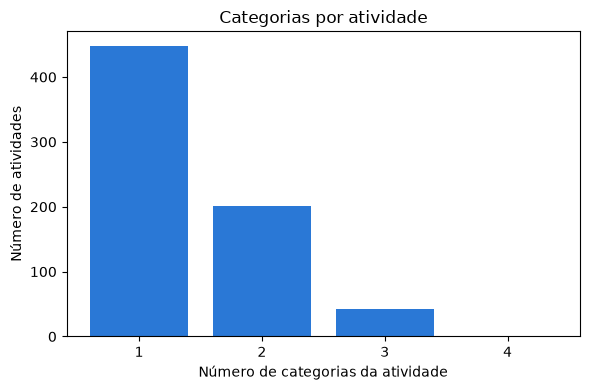

In [15]:
# ----------------------------------------------------------------------------------------------------
#                          GRÁFICO: QUANTAS CATEGORIAS CADA ATIVIDADE RECEBEU
# ----------------------------------------------------------------------------------------------------
activities_per_number_of_labels = pd.Series(number_of_labels).value_counts().sort_index()   # quantas atividades com 1, 2, 3... categorias

plt.figure(figsize=(6, 4))                                                                                            # tamanho do gráfico em polegadas
plt.bar(activities_per_number_of_labels.index.astype(str), activities_per_number_of_labels.values, color="#2a78d6")   # uma barra por tamanho de lista
plt.xlabel("Número de categorias da atividade")                                                                       # rótulo do eixo horizontal
plt.ylabel("Número de atividades")                                                                                    # rótulo do eixo vertical
plt.title("Categorias por atividade")                                                                                 # título que vai junto no artigo
plt.tight_layout()                                                                                                    # evita cortar os rótulos
plt.savefig("../docs/figures/labels_per_activity.png", dpi=150)                                                       # figura usada no artigo
plt.show()

In [16]:
# ----------------------------------------------------------------------------------------------------
#                        AS COMBINAÇÕES MAIS COMUNS E ALGUNS EXEMPLOS PARA LER
# ----------------------------------------------------------------------------------------------------
activities_with_more_than_one = activities_multilabel[activities_multilabel["number_of_labels"] >= 2]   # só quem recebeu mais de uma categoria

print("Combinações mais comuns:")
print(activities_with_more_than_one["labels"].value_counts().head(8).to_string())
print()
for piece_of_title in ["Dançando como nos filmes", "MUNDO MÁGICO", "Cine Debate - Quando a arte imita a vida", "Conexão Jovem", "PEQUENOS BRILHOS"]:
    for activity_position in np.where(activities["title"].str.contains(piece_of_title, regex=False))[0]:
        print(activities.loc[activity_position, "split"], "|", activities.loc[activity_position, "title"][:60], "->", ordered_labels[activity_position])

Combinações mais comuns:
labels
Artes Visuais | Artesanato                                     15
Artesanato | Artes Visuais                                     11
Atividade Física e Bem-Estar | Esporte                         10
Shows, Espetáculos e Performances | Cultura e Identidade        9
Shows, Espetáculos e Performances | Música                      8
Esporte | Atividade Física e Bem-Estar                          8
Sociedade e Debates | Cultura e Identidade                      8
Shows, Espetáculos e Performances | Infância e Brincadeiras     7

train | Dançando como nos filmes -> Shows, Espetáculos e Performances | Cinema
train | MUNDO MÁGICO: FESTA PARA AS CRIANÇAS -> Shows, Espetáculos e Performances | Infância e Brincadeiras
train | Cine Debate - Quando a arte imita a vida: suicídio em cena - -> Cinema
test | Conexão Jovem -> Esporte | Infância e Brincadeiras | Literatura e Leitura
train | PEQUENOS BRILHOS: A PASSARELA DA NOSSA INFÂNCIA -> Reciclagem e Sustentabilidade | I

**O que saiu.** Cada uma das 693 atividades tem agora uma lista de categorias em ordem. No treino, 179
das 554 (32%) receberam mais de uma categoria, e no teste, 66 das 139 (47%), sem nenhuma com 4.

O teste recebe mais categorias que o treino, e achamos que é porque os centros foram calculados com as
atividades de treino: cada uma delas ajudou a formar o próprio centro e por isso fica um pouco mais
perto dele do que uma atividade nova ficaria, o que deixa as fatias mais decididas.

As combinações mais comuns são as que os experimentos já indicavam: Artes Visuais com Artesanato,
Atividade Física com Esporte, Shows com Cultura e Identidade e com Música.

Os exemplos lidos mostram os dois lados. "Dançando como nos filmes" fica com Shows e Cinema, e "Mundo
Mágico" com Shows e Infância, como na leitura do experimento 5, enquanto o "Cine Debate" continua só com
Cinema, sem Sociedade e Debates. Os dois erros confiantes também continuam, com "Conexão Jovem" tendo
Esporte em 1º lugar e "Pequenos Brilhos" tendo Reciclagem em 1º, já que a régua não conserta esses
casos, e quem mede quantos eles são é a conferência humana do notebook 08.